# ML Lab: Data Preprocessing using Pandas

**Aim:** To clean and prepare a dataset using Pandas by handling missing values, removing duplicates, and applying normalization and standardization.

**Why?** Real data has blanks, repeated rows and features on very different scales. Models work best when the data is clean and comparable.

## 1. Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler

sns.set_style("whitegrid")

## 2. Create the Dataset

A small employee dataset with some **missing values** and **duplicate rows** added on purpose.

*(To use your own file instead, replace this cell with `df = pd.read_csv("your_file.csv")`.)*

In [2]:
rng = np.random.default_rng(42)
n = 60

age = rng.integers(22, 60, n).astype(float)
experience = (age - 22 - rng.integers(0, 5, n)).clip(0)
salary = (25000 + experience * 3000 + rng.normal(0, 8000, n)).round(0)

df = pd.DataFrame({
    "Age": age,
    "Experience": experience,
    "Salary": salary,
    "Performance_Score": rng.uniform(1, 5, n).round(1),
})

# Add missing values
for col, k in {"Age": 4, "Experience": 3, "Salary": 6, "Performance_Score": 4}.items():
    df.loc[rng.choice(n, k, replace=False), col] = np.nan

# Add duplicate rows
df = pd.concat([df, df.sample(5, random_state=1)], ignore_index=True)

print("Shape:", df.shape)
df.head()

Shape: (65, 4)


,Age,Experience,Salary,Performance_Score
0,25.0,0.0,18073.0,3.3
1,51.0,NaN,110746.0,NaN
2,46.0,23.0,80537.0,1.3
3,38.0,12.0,58321.0,2.7
4,38.0,14.0,68302.0,NaN


## 3. Handling Missing Values

First, find out where the values are missing.

Age                  5
Experience           3
Salary               7
Performance_Score    4
dtype: int64


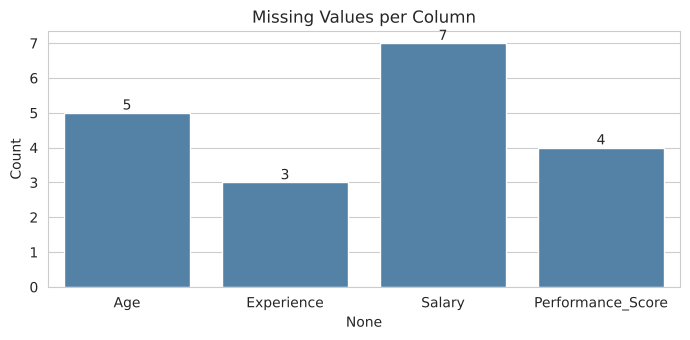

In [3]:
miss = df.isnull().sum()
print(miss)

miss = miss[miss > 0]
plt.figure(figsize=(7, 3.5))
ax = sns.barplot(x=miss.index, y=miss.values, color="steelblue")
ax.bar_label(ax.containers[0])
plt.title("Missing Values per Column")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

Now fill them in (**imputation**) instead of deleting rows, so we don't lose data:
- **Median** for Age and Experience (not affected by extreme values)
- **Mean** for Salary and Performance_Score

In [4]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Experience"] = df["Experience"].fillna(df["Experience"].median())
df["Salary"] = df["Salary"].fillna(df["Salary"].mean())
df["Performance_Score"] = df["Performance_Score"].fillna(df["Performance_Score"].mean())

print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


## 4. Removing Duplicates

Repeated rows can bias a model, so we find them with `duplicated()` and remove them with `drop_duplicates()`.

In [5]:
print("Duplicate rows found:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)

print("Duplicates left:", df.duplicated().sum())
print("Final shape:", df.shape)

Duplicate rows found: 5
Duplicates left: 0
Final shape: (60, 4)


## 5. Normalization (Min-Max Scaling)

Scales every value to the range **0 to 1**:

$$x' = \frac{x - x_{min}}{x_{max} - x_{min}}$$

In [6]:
df_norm = pd.DataFrame(MinMaxScaler().fit_transform(df), columns=df.columns)
df_norm.describe().round(2)

,Age,Experience,Salary,Performance_Score
count,60.00,60.00,60.00,60.00
mean,0.51,0.47,0.51,0.48
std,0.28,0.28,0.25,0.29
min,0.00,0.00,0.00,0.00
25%,0.33,0.27,0.37,0.26
50%,0.53,0.51,0.52,0.48
75%,0.75,0.70,0.72,0.72
max,1.00,1.00,1.00,1.00


## 6. Standardization (Z-score Scaling)

Scales every feature to **mean = 0** and **standard deviation = 1**:

$$z = \frac{x - \mu}{\sigma}$$

In [7]:
df_std = pd.DataFrame(StandardScaler().fit_transform(df), columns=df.columns)
df_std.describe().round(2)

,Age,Experience,Salary,Performance_Score
count,60.00,60.00,60.00,60.00
mean,-0.00,-0.00,-0.00,0.00
std,1.01,1.01,1.01,1.01
min,-1.82,-1.68,-2.10,-1.66
25%,-0.64,-0.71,-0.58,-0.78
50%,0.08,0.17,0.03,-0.00
75%,0.84,0.85,0.83,0.83
max,1.72,1.92,1.99,1.78


## 7. Visualizations

### 7.1 Bar chart: spread of features before and after scaling

Salary's spread is thousands of times bigger than the other features. After scaling, all features have comparable spread. *(Log scale is used so every bar is visible.)*

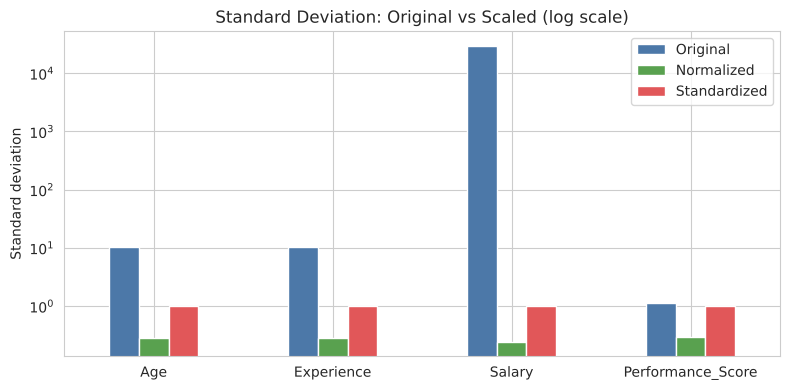

In [8]:
spread = pd.DataFrame({
    "Original": df.std(ddof=0),
    "Normalized": df_norm.std(ddof=0),
    "Standardized": df_std.std(ddof=0),
})

spread.plot(kind="bar", logy=True, figsize=(8, 4), color=["#4c78a8", "#59a14f", "#e15759"])
plt.title("Standard Deviation: Original vs Scaled (log scale)")
plt.ylabel("Standard deviation")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 7.2 Correlation heatmap

Shows how strongly features move together (+1 = rise together, -1 = opposite, 0 = no relationship). Correlation is not changed by scaling, so we use the cleaned data.

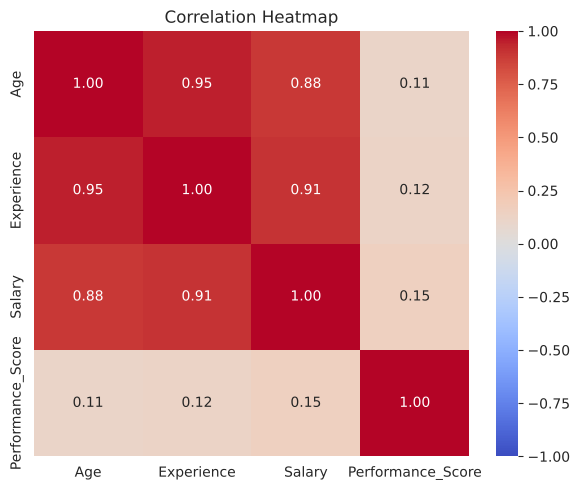

In [9]:
plt.figure(figsize=(6, 5))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## 8. Conclusion

- Missing values were filled using the **median/mean**.
- Duplicate rows were removed with `drop_duplicates()`.
- Features were scaled using **Min-Max normalization** (0 to 1) and **Z-score standardization** (mean 0, std 1).
- A bar chart and a correlation heatmap were used to understand the data.

The dataset is now clean and ready for model training.